# 3. Welche Modelle sagen das Überleben am besten voraus?

Wir vergleichen drei verschiedene Ansätze: logistische Regression, Entscheidungsbaum und die Methode der nächsten Nachbarn (KNN). Beim Entscheidungsbaum prüfen wir eine einfache und eine ausführlichere Variante.

Jeder Modelltyp wird mit den zehn Gruppen von Merkmalen aus [Notebook 2](02_Feature_Engineering_und_Auswahl.ipynb) kombiniert. Wir verwenden 712 Personen zur Entwicklung und 179 für einen abschließenden Kontrollvergleich.

Die Daten wurden zuvor vollständig beschrieben. Die 179 Kontrollpersonen sind deshalb keine völlig neue, unbekannte Stichprobe.


In [1]:
# Gestaltung der Abbildungen.
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
COLORS = {'dk2': '#732124', 'lt2': '#F0EDE5', 'accent1': '#D34817', 'accent2': '#A68D65', 'accent3': '#728377', 'accent4': '#B4797B', 'accent5': '#CE8439', 'accent6': '#CF3A2A', 'hlink': '#D06853', 'folHlink': '#B67779'}
MAJOR_FONTS = ('Rockwell Nova Light', 'Rockwell Nova', 'Rockwell', 'DejaVu Serif')
MINOR_FONTS = ('Avenir Next LT Pro Light', 'Avenir Next LT Pro', 'Avenir Next', 'Calibri Light', 'Calibri', 'DejaVu Sans')
LEAF_CMAP = LinearSegmentedColormap.from_list('leaf', [COLORS['lt2'], COLORS['accent4'], COLORS['dk2']])
LEAF_CMAP.set_bad(COLORS['lt2'])

def heatmap_text_color(value, vmin=0, vmax=1):
    background = LEAF_CMAP((value - vmin) / (vmax - vmin))[:3]

    def luminance(rgb):
        linear = [v / 12.92 if v <= 0.04045 else ((v + 0.055) / 1.055) ** 2.4 for v in rgb]
        return sum((v * w for v, w in zip(linear, [0.2126, 0.7152, 0.0722])))
    luminance_background = luminance(background)

    def contrast(color):
        light = luminance(to_rgb(color))
        return (max(light, luminance_background) + 0.05) / (min(light, luminance_background) + 0.05)
    return max((COLORS['dk2'], COLORS['lt2']), key=contrast)

def resolved_fonts():
    available = {font.name for font in fm.fontManager.ttflist}
    major = next((name for name in MAJOR_FONTS if name in available))
    minor = next((name for name in MINOR_FONTS if name in available))
    return {'requested_heading': MAJOR_FONTS[0], 'heading': major, 'requested_body': MINOR_FONTS[0], 'body': minor, 'heading_file': fm.findfont(fm.FontProperties(family=major)), 'body_file': fm.findfont(fm.FontProperties(family=minor))}

def apply_leaf_theme():
    fonts = resolved_fonts()
    mpl.rcParams.update({'font.family': fonts['body'], 'font.size': 11, 'font.weight': 'normal', 'text.color': COLORS['dk2'], 'figure.facecolor': COLORS['lt2'], 'axes.facecolor': COLORS['lt2'], 'savefig.facecolor': COLORS['lt2'], 'savefig.transparent': False, 'axes.edgecolor': COLORS['accent2'], 'axes.linewidth': 0.7, 'axes.labelcolor': COLORS['dk2'], 'axes.labelsize': 11, 'axes.labelpad': 10, 'axes.titlesize': 13, 'axes.titleweight': 'normal', 'axes.titlepad': 14, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True, 'axes.prop_cycle': cycler(color=[COLORS[f'accent{i}'] for i in range(1, 7)]), 'xtick.color': COLORS['dk2'], 'ytick.color': COLORS['dk2'], 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'xtick.major.size': 0, 'ytick.major.size': 0, 'xtick.major.pad': 7, 'ytick.major.pad': 7, 'grid.color': COLORS['accent2'], 'grid.alpha': 0.22, 'grid.linewidth': 0.6, 'grid.linestyle': '-', 'legend.frameon': False, 'legend.fontsize': 10, 'lines.linewidth': 1.7, 'patch.linewidth': 0.8, 'boxplot.boxprops.color': COLORS['dk2'], 'boxplot.whiskerprops.color': COLORS['dk2'], 'boxplot.capprops.color': COLORS['dk2'], 'boxplot.medianprops.color': COLORS['dk2'], 'boxplot.flierprops.markeredgecolor': COLORS['dk2'], 'boxplot.flierprops.markerfacecolor': COLORS['lt2'], 'savefig.dpi': 300})
    return fonts

def _wrap_to_width(text, renderer, font_properties, max_width):
    lines = []
    for paragraph in text.split('\n'):
        line = ''
        for word in paragraph.split():
            candidate = f'{line} {word}'.strip()
            width = renderer.get_text_width_height_descent(candidate, font_properties, False)[0]
            if line and width > max_width:
                lines.append(line)
                line = word
            else:
                line = candidate
        lines.append(line)
    return '\n'.join(lines)

def decorate_leaf_figure(fig, number, title, note):
    fonts = resolved_fonts()
    heading = fm.FontProperties(family=fonts['heading'], size=17)
    body = fm.FontProperties(family=fonts['body'], size=9)
    fig.set_facecolor(COLORS['lt2'])
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width_pixels, height_pixels = (fig.bbox.width, fig.bbox.height)
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
    title_text = _wrap_to_width(title, renderer, heading, 0.91 * width_pixels)
    note_text = _wrap_to_width('Anmerkung. ' + note, renderer, body, 0.91 * width_pixels)
    number_label = f'{number:02d}' if isinstance(number, int) else str(number)
    top_label = fig.text(0.045, 0.965, f'ABBILDUNG {number_label}', color=COLORS['accent1'], family=fonts['body'], fontsize=9, va='top')
    title_artist = fig.text(0.045, 0.91, title_text, fontproperties=heading, color=COLORS['dk2'], va='top', linespacing=1.12)
    note_artist = fig.text(0.045, 0.035, note_text, fontproperties=body, color=COLORS['dk2'], va='bottom', linespacing=1.3)
    fig.canvas.draw()
    title_box = title_artist.get_window_extent(renderer)
    note_box = note_artist.get_window_extent(renderer)
    top = title_box.y0 / height_pixels - 0.055
    bottom = note_box.y1 / height_pixels + 0.055
    if top - bottom < 0.28:
        raise ValueError('Figure is too short for its title/note; increase figsize height.')
    if fig.legends:
        for legend in fig.legends:
            for text in legend.get_texts():
                text.set_text(deutsch(text.get_text()))
            legend.set_loc('upper center')
            legend.set_bbox_to_anchor((0.5, top))
        fig.canvas.draw()
        top = min((legend.get_window_extent(renderer).y0 / height_pixels for legend in fig.legends)) - 0.035
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
        if ax.get_legend() is not None:
            for text in ax.get_legend().get_texts():
                text.set_text(deutsch(text.get_text()))
        ax.set_facecolor(COLORS['lt2'])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        is_colorbar = hasattr(ax, '_colorbar')
        if ax.images or is_colorbar:
            ax.grid(False)
        elif ax.axison:
            horizontal = any((getattr(container, 'orientation', None) == 'horizontal' for container in ax.containers))
            horizontal = horizontal or 'fehlender' in ax.get_xlabel() or ax.get_xlabel() == 'Beobachtete Überlebensquote'
            ax.grid(axis='x' if horizontal else 'y')
        ax.title.set_fontfamily(fonts['heading'])
        ax.set_axisbelow(True)
    fig.add_artist(Line2D([0.045, 0.12], [top + 0.027, top + 0.027], transform=fig.transFigure, color=COLORS['accent1'], linewidth=2.5, solid_capstyle='butt'))
    fig.add_artist(Line2D([0.045, 0.955], [bottom - 0.022, bottom - 0.022], transform=fig.transFigure, color=COLORS['accent2'], linewidth=0.6, alpha=0.55))
    fig.tight_layout(rect=[0.025, bottom, 0.98, top], pad=1.1, w_pad=2.5)
    return (top_label, title_artist, note_artist)

def save_leaf_figure(fig, number, title, note, destination, *, show=True, dpi=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    decorate_leaf_figure(fig, number, deutsch(title), deutsch(note))
    fig.savefig(destination.with_suffix('.png'), dpi=dpi)
    if show:
        plt.show()
    plt.close(fig)

import pandas as pd
from IPython.display import display as _display

BEZEICHNUNGEN = {
    'Accuracy': 'Genauigkeit', 'CV-Accuracy': 'Mittlere Prüfgenauigkeit',
    'CV-F1': 'Mittlerer F1-Wert', 'CV-ROC AUC': 'Mittlere Fläche unter der Prüfkurve',
    'CV-Brier': 'Mittlerer Wahrscheinlichkeitsfehler', 'Fold-SD': 'Streuung der Prüfergebnisse',
    'Precision': 'Anteil richtiger Überlebensvorhersagen', 'Recall': 'Anteil erkannter Überlebender',
    'F1': 'F1-Wert', 'ROC AUC': 'Fläche unter der Prüfkurve',
    'Brier score': 'Wahrscheinlichkeitsfehler', "Cohen's kappa": 'Übereinstimmung über Zufallsniveau',
    'Feature': 'Merkmal', 'Coefficient': 'Gewicht', 'Feature importance': 'Merkmalsbedeutung',
    'Distance': 'Abstand', 'VoteWeight': 'Stimmgewicht', 'VoteShare': 'Stimmanteil',
    'Mean': 'Mittelwert', 'Standard deviation': 'Standardabweichung',
    '25% Quantile': 'Unteres Viertel', '75% Quantile': 'Oberes Viertel',
    'Binary target': 'Ergebnis mit zwei Werten', 'Ordinal category': 'Geordnete Kategorie',
    'Nominal category': 'Ungeordnete Kategorie', 'Candidate': 'Kombination',
    'Fold': 'Prüfdurchgang', 'Rank': 'Rang', 'Training': 'Genauigkeit in den Lerndaten',
    'Encoded columns': 'Anzahl aufbereiteter Merkmale',
    'Known holdout Accuracy': 'Genauigkeit im Kontrollvergleich',
    'Nested Personen Accuracy': 'Zusätzliche Prüfgenauigkeit (Personen)',
    'Nested Ticketgruppen Accuracy': 'Zusätzliche Prüfgenauigkeit (Ticketgruppen)',
    'Logistic Regression': 'Logistische Regression', 'Decision Tree': 'Entscheidungsbaum',
    'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
    'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
    'female': 'Weiblich', 'n_neighbors': 'Anzahl Nachbarn', 'p': 'Abstandsmaß', 'weights': 'Gewichtung', 'uniform': 'Gleichmäßig', 'distance': 'Nach Abstand', 'male': 'Männlich', 'Other': 'Sonstige',
    'Train': 'Trainingsdaten', 'Kaggle-Test': 'Testdaten',
}

def display(*werte):
    for wert in werte:
        if isinstance(wert, (pd.DataFrame, pd.Series)):
            wert = wert.copy()
            if isinstance(wert, pd.Series):
                wert = wert.to_frame()
            wert = wert.rename(columns=BEZEICHNUNGEN, index=BEZEICHNUNGEN)
            for spalte in wert.select_dtypes(include=['object', 'str']).columns:
                wert[spalte] = wert[spalte].replace(BEZEICHNUNGEN)
        if isinstance(wert, Markdown):
            wert = Markdown(deutsch(wert.data))
        _display(wert)


def deutsch(text):
    for vorher, nachher in {
        'Logistic Regression': 'Logistische Regression',
        'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
        'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
        'Decision Tree': 'Entscheidungsbaum',
        'Confusion Matrices': 'Richtige und falsche Vorhersagen',
        'Accuracy': 'Genauigkeit', 'Nested Personen-CV': 'zusätzlichen Personenprüfung',
        'Nested CV': 'zusätzliche Prüfung der Auswahl',
        'Outer fold': 'äußerer Prüfdurchgang', 'Auswahl-Folds': 'Prüfdurchgänge',
        'Training fold': 'Lerngruppe', 'Training folds': 'Lerngruppen',
        'Bekanntes Holdout': 'Kontrollvergleich', 'bekanntes Holdout': 'Kontrollvergleich', 'Holdout': 'Kontrolldatensatz',
        'Featuregruppe': 'Merkmalsgruppe', 'Feature': 'Merkmal',
        'Mean': 'Mittelwert', 'Target': 'Überleben',
        'standardized': 'bei gleicher Gruppenzusammensetzung',
        'Standardization': 'Angleichung der Gruppenzusammensetzung',
        'Median Imputation': 'Ergänzung mit dem mittleren Wert',
        'Labels': 'bekannte Ergebnisse', 'labels': 'bekannte Ergebnisse',
        'Log-Odds': 'Gewichte im Modell', 'Preprocessing': 'Datenvorbereitung',
        'Train:': 'Trainingsdaten:', 'Train (': 'Trainingsdaten (',
        'vollständigem Train': 'vollständigen Trainingsdaten',
        'nur Train': 'nur Trainingsdaten', '(Train)': '(Trainingsdaten)',
        'Nutzergrenzen nach Deckplänen': 'Vereinfachte Zuordnung',
        'keine testseitigen Überlebenslabels': 'Überleben der Testpersonen unbekannt',
        'Standardentscheidung': 'gewöhnliche Entscheidungsregel',
        'getunte Auswahlwerte sind optimistisch': 'die besten Auswahlwerte können zu günstig ausfallen',
        'CV': 'Kreuzvalidierung', 'Folds': 'Prüfgruppen',
        'female': 'weiblich', 'male': 'männlich',
    }.items():
        text = text.replace(vorher, nachher)
    return text




In [2]:
import json
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, brier_score_loss, cohen_kappa_score
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

class FoldLocalTicketFeatures(TransformerMixin, BaseEstimator):

    def fit(self, X, y=None):
        tickets = X.Ticket.str.strip().str.upper()
        self.ticket_counts_ = tickets.value_counts()
        self.child_tickets_ = frozenset(tickets[X.Age.lt(18)].dropna())
        self.fit_passenger_ids_ = tuple(X.PassengerId) if 'PassengerId' in X else ()
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        result = X.copy()
        tickets = X.Ticket.str.strip().str.upper()
        result['ErwachsenerKinderticket'] = (X.Age.ge(18) & tickets.isin(self.child_tickets_)).astype(int)
        counts = tickets.map(self.ticket_counts_).fillna(1).clip(lower=1)
        result['LogFahrpreisProPerson'] = np.log1p(X.Fare / counts)
        return result
MODEL_TYPES = {'Logistic Regression': LogisticRegression(max_iter=2000), 'Shallow Decision Tree': DecisionTreeClassifier(random_state=42), 'Extended Decision Tree': DecisionTreeClassifier(criterion='entropy', random_state=42), 'KNN': KNeighborsClassifier(algorithm='brute', n_jobs=1)}
PARAMETER_GRIDS = {'Logistic Regression': {'C': [0.1, 1.0, 10.0]}, 'Shallow Decision Tree': {'max_depth': [2, 3], 'min_samples_leaf': [15, 30]}, 'Extended Decision Tree': {'max_depth': [4, 7], 'min_samples_leaf': [5, 15]}, 'KNN': {'n_neighbors': [5, 15, 31], 'p': [1, 2], 'weights': ['uniform', 'distance']}}
FAMILIES = {'Logistic Regression': 'Logistic Regression', 'Shallow Decision Tree': 'Decision Tree', 'Extended Decision Tree': 'Decision Tree', 'KNN': 'KNN'}
CONTINUOUS = {'Age', 'SibSp', 'Parch', 'Fare', 'LogFahrpreisProPerson'}

def preprocessing(columns):
    numeric = [name for name in columns['numerisch'] if name in CONTINUOUS]
    indicators = [name for name in columns['numerisch'] if name not in CONTINUOUS]
    blocks = [('numerisch', Pipeline([('ergänzen', SimpleImputer(strategy='median', keep_empty_features=True)), ('skalieren', StandardScaler())]), numeric), ('kategorisch', Pipeline([('ergänzen', SimpleImputer(strategy='constant', fill_value='Unbekannt', keep_empty_features=True)), ('kodieren', OneHotEncoder(drop=None, min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False))]), columns['kategorisch'])]
    if indicators:
        blocks.append(('indikatoren', SimpleImputer(strategy='constant', fill_value=0, keep_empty_features=True), indicators))
    return ColumnTransformer(blocks, verbose_feature_names_out=False)

def make_pipeline(model_type, columns, parameters):
    return Pipeline([('ticketmerkmale', FoldLocalTicketFeatures()), ('vorbereitung', preprocessing(columns)), ('modell', clone(MODEL_TYPES[model_type]).set_params(**parameters))])

def metrics(y, prediction, probability):
    return {'Accuracy': accuracy_score(y, prediction), 'Precision': precision_score(y, prediction, zero_division=0), 'Recall': recall_score(y, prediction, zero_division=0), 'F1': f1_score(y, prediction, zero_division=0), 'ROC AUC': roc_auc_score(y, probability), 'Brier score': brier_score_loss(y, probability), "Cohen's kappa": cohen_kappa_score(y, prediction)}

def candidates(groups):
    return [{'Candidate': f'c{index:04d}', 'Modell': model_type, 'Familie': FAMILIES[model_type], 'Merkmalsgruppe': group, 'Parameter': json.dumps(parameters, sort_keys=True)} for index, (model_type, group, parameters) in enumerate(((model_type, group, parameters) for model_type in MODEL_TYPES for group in groups for parameters in ParameterGrid(PARAMETER_GRIDS[model_type])), start=1)]

def exhaustive_search(X, y, groups, folds, *, ticket_groups=None):
    assert len(folds) == 5
    specs = candidates(groups)
    seen = np.zeros(len(X), dtype=int)
    fold_records = []
    for fold, (train_index, validation_index) in enumerate(folds, start=1):
        assert set(train_index).isdisjoint(validation_index)
        if ticket_groups is not None:
            assert set(ticket_groups.iloc[train_index]).isdisjoint(ticket_groups.iloc[validation_index])
        seen[validation_index] += 1
        X_train, X_validation = (X.iloc[train_index], X.iloc[validation_index])
        y_train, y_validation = (y.iloc[train_index], y.iloc[validation_index])
        assert y_train.nunique() == y_validation.nunique() == 2
        ticket_features = FoldLocalTicketFeatures().fit(X_train)
        train_features = ticket_features.transform(X_train)
        validation_features = ticket_features.transform(X_validation)
        for group, columns in groups.items():
            transformer = preprocessing(columns)
            train_array = transformer.fit_transform(train_features)
            validation_array = transformer.transform(validation_features)
            assert np.isfinite(train_array).all() and np.isfinite(validation_array).all()
            for spec in specs:
                if spec['Merkmalsgruppe'] != group:
                    continue
                estimator = clone(MODEL_TYPES[spec['Modell']]).set_params(**json.loads(spec['Parameter']))
                estimator.fit(train_array, y_train)
                prediction = estimator.predict(validation_array)
                probability = estimator.predict_proba(validation_array)[:, 1]
                fold_records.append({**spec, 'Fold': fold, 'Personen': len(validation_index), **metrics(y_validation, prediction, probability), 'Training': accuracy_score(y_train, estimator.predict(train_array)), 'Encoded columns': train_array.shape[1]})
    assert (seen == 1).all(), 'Every passenger must be validated exactly once.'
    details = pd.DataFrame(fold_records)
    assert details.groupby('Candidate').size().eq(5).all()
    key = ['Candidate', 'Modell', 'Familie', 'Merkmalsgruppe', 'Parameter']
    summary = details.groupby(key, sort=False).agg(**{'CV-Accuracy': ('Accuracy', 'mean'), 'Fold-SD': ('Accuracy', 'std'), 'CV-F1': ('F1', 'mean'), 'CV-ROC AUC': ('ROC AUC', 'mean'), 'CV-Brier': ('Brier score', 'mean'), 'Training': ('Training', 'mean'), 'Encoded columns': ('Encoded columns', 'mean')}).reset_index()
    summary = summary.sort_values(['CV-Accuracy', 'Fold-SD', 'Candidate'], ascending=[False, True, True], kind='stable').reset_index(drop=True)
    summary['Rank'] = np.arange(1, len(summary) + 1)
    summary['Gewählt'] = summary.Candidate.eq(summary.iloc[0].Candidate)
    return (summary, details)

def selected_row(search, *, family=None, model_type=None):
    result = search
    if family is not None:
        result = result[result.Familie.eq(family)]
    if model_type is not None:
        result = result[result.Modell.eq(model_type)]
    return result.iloc[0]

def pipeline_from_row(row, groups):
    parameters = row['Parameter']
    if isinstance(parameters, str):
        parameters = json.loads(parameters)
    return make_pipeline(row['Modell'], groups[row['Merkmalsgruppe']], parameters)



In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.base import clone
pd.set_option('display.precision', 4)
ERGEBNISSE, ABBILDUNGEN = (Path('ergebnisse'), Path('abbildungen/03_modellvergleich'))
ERGEBNISSE.mkdir(exist_ok=True)
ABBILDUNGEN.mkdir(parents=True, exist_ok=True)
apply_leaf_theme()
daten = pd.read_csv(ERGEBNISSE / 'train_merkmale.csv')
gruppen = json.loads((ERGEBNISSE / 'merkmalsgruppen.json').read_text(encoding='utf-8'))
assert daten.PassengerId.is_unique and len(daten) == 891
assert len(gruppen) == 10
assert all(({'Sex', 'Pclass', 'Age'} <= set(s['numerisch'] + s['kategorisch']) for s in gruppen.values()))
entwicklung_index, holdout_index = train_test_split(daten.index, test_size=0.2, stratify=daten.Survived, random_state=42)
entwicklung = daten.loc[entwicklung_index].reset_index(drop=True)
holdout = daten.loc[holdout_index].reset_index(drop=True)
assert set(entwicklung.PassengerId).isdisjoint(holdout.PassengerId)
aufteilung = pd.concat([entwicklung[['PassengerId']].assign(Bereich='Entwicklung'), holdout[['PassengerId']].assign(Bereich='Prüfung')], ignore_index=True)
aufteilung.to_csv(ERGEBNISSE / 'datenaufteilung.csv', index=False)
ziel = entwicklung.Survived.copy()
X = entwicklung.drop(columns='Survived')
tickets = X.Ticket.str.strip().str.upper()
print(deutsch(f'Entwicklung: {len(X)}; bekanntes Holdout: {len(holdout)}.'))
display(pd.DataFrame([{'Modell': k, 'Ansatz': FAMILIES[k], 'Raster': v} for k, v in PARAMETER_GRIDS.items()]))
print(deutsch(f'{len(gruppen)} Featuregruppen × 4 Modelltypen; {len(candidates(gruppen))} Konfigurationen pro Suche.'))



Entwicklung: 712; Kontrollvergleich: 179.


,Modell,Ansatz,Raster
0,Logistische Regression,Logistische Regression,"{'C': [0.1, 1.0, 10.0]}"
1,Einfacher Entscheidungsbaum,Entscheidungsbaum,"{'max_depth': [2, 3], 'min_samples_leaf': [15,..."
2,Erweiterter Entscheidungsbaum,Entscheidungsbaum,"{'max_depth': [4, 7], 'min_samples_leaf': [5, ..."
3,KNN,KNN,"{'n_neighbors': [5, 15, 31], 'p': [1, 2], 'wei..."


10 Merkmalsgruppen × 4 Modelltypen; 230 Konfigurationen pro Suche.


## Gleiche Bedingungen für alle Modelle

Wir prüfen insgesamt 230 Kombinationen von Merkmalen und Modelleinstellungen. Dazu gehören die Anzahl ähnlicher Personen bei KNN, die Größe des Entscheidungsbaums und die Stärke der Begrenzung bei der Regression.

Jede Kombination wird fünfmal geprüft: Vier Teile der Entwicklungsdaten dienen zum Lernen, der fünfte zum Prüfen. Jeder Teil ist einmal an der Reihe. Dieses Vorgehen heißt Kreuzvalidierung.

Fehlende Werte und gemeinsame Tickets werden jeweils nur anhand der Lerndaten verarbeitet. Das tatsächliche Überleben steht keinem Modell als Eingabe zur Verfügung.


In [4]:
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X, ziel))
gruppen_folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X, ziel, tickets))
fold_ids = []
for name, split_list in [('Personen', folds), ('Ticketgruppen', gruppen_folds)]:
    for fold, (training, validierung) in enumerate(split_list, start=1):
        if name == 'Ticketgruppen':
            assert set(tickets.iloc[training]).isdisjoint(tickets.iloc[validierung])
        fold_ids.append(pd.DataFrame({'PassengerId': X.iloc[validierung].PassengerId, 'Bewertung': name, 'Fold': fold}))
suchverlauf, fold_werte = exhaustive_search(X, ziel, gruppen, folds)
suchverlauf.to_csv(ERGEBNISSE / 'modell_suchverlauf.csv', index=False)
fold_werte.to_csv(ERGEBNISSE / 'modell_folds.csv', index=False)
assert len(suchverlauf) == 230 and len(fold_werte) == 230 * 5
assert suchverlauf.groupby(['Modell', 'Merkmalsgruppe']).size().shape[0] == len(MODEL_TYPES) * len(gruppen)
assert np.isfinite(suchverlauf[['CV-Accuracy', 'Fold-SD', 'CV-F1', 'CV-ROC AUC', 'CV-Brier']]).all().all()
display(suchverlauf.head(20))



,Kombination,Modell,Familie,Merkmalsgruppe,Parameter,Mittlere Prüfgenauigkeit,Streuung der Prüfergebnisse,Mittlerer F1-Wert,Mittlere Fläche unter der Prüfkurve,Mittlerer Wahrscheinlichkeitsfehler,Genauigkeit in den Lerndaten,Anzahl aufbereiteter Merkmale,Rang,Gewählt
0,c0225,KNN,KNN,Titel + Familie + Logpreis,"{""n_neighbors"": 15, ""p"": 2, ""weights"": ""uniform""}",0.8300,0.0320,0.7585,0.8743,0.1295,0.8413,20.0,1,True
1,c0028,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,"{""C"": 0.1}",0.8287,0.0245,0.7726,0.8681,0.1339,0.8251,20.0,2,False
2,c0223,KNN,KNN,Titel + Familie + Logpreis,"{""n_neighbors"": 15, ""p"": 1, ""weights"": ""uniform""}",0.8272,0.0294,0.7517,0.8714,0.1302,0.8423,20.0,3,False
3,c0187,KNN,KNN,Rohdaten + Deck/Lage,"{""n_neighbors"": 15, ""p"": 1, ""weights"": ""uniform""}",0.8259,0.0194,0.7441,0.8652,0.1335,0.8395,22.0,4,False
4,c0105,Erweiterter Entscheidungsbaum,Entscheidungsbaum,Alle entwickelten Merkmale,"{""max_depth"": 7, ""min_samples_leaf"": 5}",0.8245,0.0204,0.7517,0.8296,0.1489,0.8789,42.2,5,False
5,c0177,KNN,KNN,Rohdaten + Deck,"{""n_neighbors"": 15, ""p"": 2, ""weights"": ""uniform""}",0.8244,0.0139,0.7496,0.8575,0.1376,0.8378,20.2,6,False
6,c0163,KNN,KNN,Rohdaten + Kinderticket,"{""n_neighbors"": 15, ""p"": 1, ""weights"": ""uniform""}",0.8230,0.0250,0.7430,0.8626,0.1346,0.8371,14.0,7,False
7,c0165,KNN,KNN,Rohdaten + Kinderticket,"{""n_neighbors"": 15, ""p"": 2, ""weights"": ""uniform""}",0.8230,0.0225,0.7463,0.8568,0.1387,0.8322,14.0,8,False
8,c0175,KNN,KNN,Rohdaten + Deck,"{""n_neighbors"": 15, ""p"": 1, ""weights"": ""uniform""}",0.8217,0.0178,0.7394,0.8622,0.1353,0.8371,20.2,9,False
9,c0029,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,"{""C"": 1.0}",0.8216,0.0360,0.7643,0.8742,0.1289,0.8294,20.0,10,False


## Welche Angaben helfen welchem Modell?

Die Tabelle zeigt für jede Gruppe von Merkmalen und jeden Modelltyp den mittleren Anteil richtiger Vorhersagen. „Accuracy“ bezeichnet diesen Anteil: 0,80 bedeutet 80 % richtige Vorhersagen.

Wir zeigen jeweils die beste geprüfte Einstellung. Da viele Einstellungen verglichen werden, können die höchsten Werte zu optimistisch ausfallen. Deshalb folgt eine zusätzliche Prüfung.


Modell,Logistische Regression,Einfacher Entscheidungsbaum,Erweiterter Entscheidungsbaum,KNN
Merkmalsgruppe,,,,
Rohdaten,0.8034,0.8062,0.8132,0.8188
Rohdaten + Status,0.8034,0.8062,0.8132,0.8202
Rohdaten + Alter fehlt,0.8062,0.8062,0.8132,0.8188
Familie + Status,0.8104,0.8062,0.8175,0.8188
Rohdaten + Kinderticket,0.8034,0.8062,0.8132,0.8230
Rohdaten + Deck,0.8090,0.7950,0.7992,0.8244
Rohdaten + Deck/Lage,0.8146,0.7950,0.8062,0.8259
Rohdaten + Deck/Lage + Alter fehlt,0.8090,0.7950,0.8118,0.8188
Alle entwickelten Merkmale,0.8118,0.7893,0.8245,0.8132


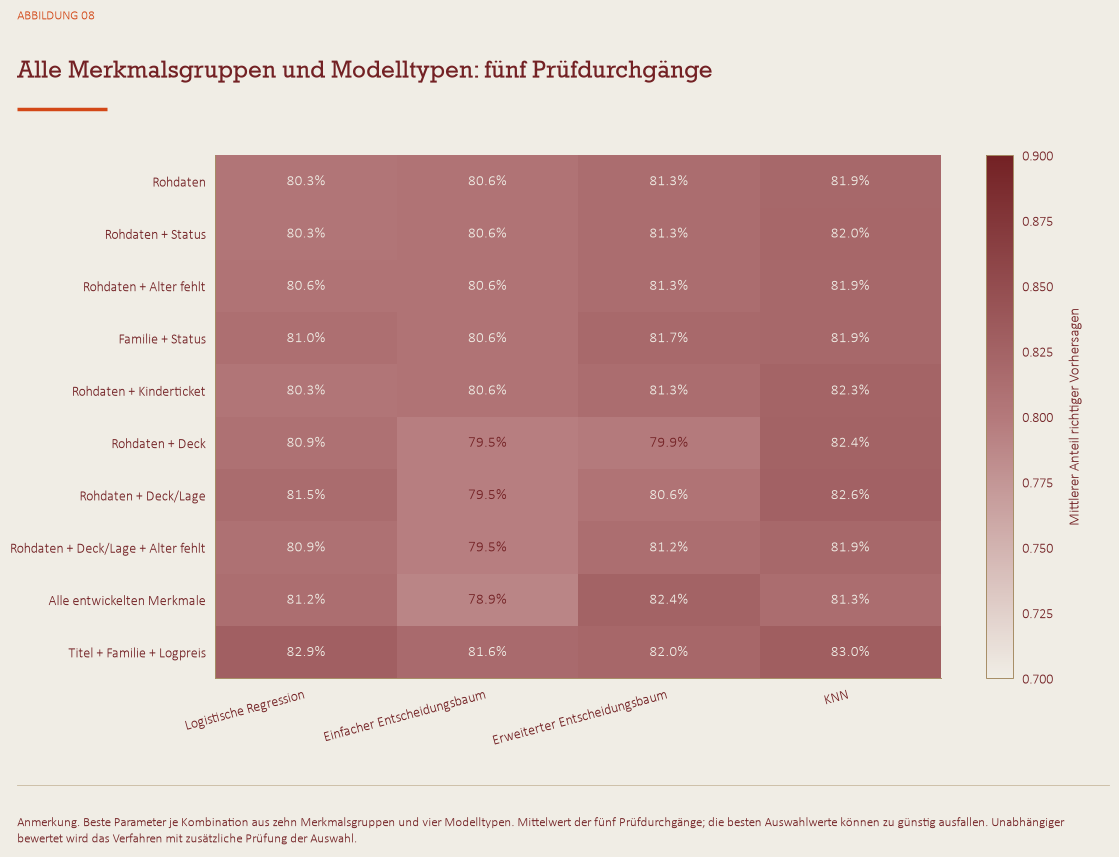

,Modell,Vergleich,Genauigkeitsunterschied (Prozentpunkte)
0,Logistische Regression,Status,0.0000
1,Logistische Regression,Alter fehlt,0.2807
2,Logistische Regression,Familiengruppe,0.7003
3,Logistische Regression,Kinderticket,-0.0010
4,Logistische Regression,Deck,0.5624
5,Logistische Regression,Lage zusätzlich zum Deck,0.5624
6,Logistische Regression,Alter fehlt zusätzlich zur Lage,-0.5614
7,Einfacher Entscheidungsbaum,Status,0.0000
8,Einfacher Entscheidungsbaum,Alter fehlt,0.0000
9,Einfacher Entscheidungsbaum,Familiengruppe,0.0000


Ablation mit jeweils getunten Parametern: Unterschiede gelten für das Gesamtverfahren, nicht für isolierte kausale Merkmännlichffekte.


In [5]:
vergleich = suchverlauf.drop_duplicates(['Modell', 'Merkmalsgruppe']).copy()
vergleich = vergleich.sort_values(['Modell', 'Merkmalsgruppe'])
vergleich.to_csv(ERGEBNISSE / 'feature_vergleich.csv', index=False)
matrix = vergleich.pivot(index='Merkmalsgruppe', columns='Modell', values='CV-Accuracy')
matrix = matrix.reindex(index=list(gruppen), columns=list(MODEL_TYPES))
assert matrix.shape == (10, 4) and matrix.notna().all().all()
display(matrix)
fig, ax = plt.subplots(figsize=(12, 9))
heat = ax.imshow(matrix, cmap=LEAF_CMAP, vmin=0.7, vmax=0.9, aspect='auto')
ax.set_xticks(range(len(matrix.columns)), [BEZEICHNUNGEN.get(v, v) for v in matrix.columns], rotation=15, ha='right')
ax.set_yticks(range(len(matrix.index)), matrix.index)
for i in range(len(matrix)):
    for j in range(len(matrix.columns)):
        ax.text(j, i, f'{matrix.iloc[i, j]:.1%}', ha='center', va='center', color=heatmap_text_color(matrix.iloc[i, j], 0.7, 0.9))
fig.colorbar(heat, ax=ax, label='Mittlerer Anteil richtiger Vorhersagen')
save_leaf_figure(fig, 8, 'Alle Merkmalsgruppen und Modelltypen: fünf Prüfdurchgänge', 'Beste Parameter je Kombination aus zehn Featuregruppen und vier Modelltypen. Mittelwert der fünf Auswahl-Folds; getunte Auswahlwerte sind optimistisch. Unabhängiger bewertet wird das Verfahren mit Nested CV.', ABBILDUNGEN / '08_alle_feature_modelle')
paare = [('Status', 'Rohdaten', 'Rohdaten + Status'), ('Alter fehlt', 'Rohdaten', 'Rohdaten + Alter fehlt'), ('Familiengruppe', 'Rohdaten + Status', 'Familie + Status'), ('Kinderticket', 'Rohdaten', 'Rohdaten + Kinderticket'), ('Deck', 'Rohdaten', 'Rohdaten + Deck'), ('Lage zusätzlich zum Deck', 'Rohdaten + Deck', 'Rohdaten + Deck/Lage'), ('Alter fehlt zusätzlich zur Lage', 'Rohdaten + Deck/Lage', 'Rohdaten + Deck/Lage + Alter fehlt')]
ablation = pd.DataFrame([{'Modell': model_type, 'Vergleich': label, 'Genauigkeitsunterschied (Prozentpunkte)': 100 * (matrix.loc[after, model_type] - matrix.loc[before, model_type])} for model_type in MODEL_TYPES for label, before, after in paare])
ablation.to_csv(ERGEBNISSE / 'feature_ablation.csv', index=False)
display(ablation)
print(deutsch('Ablation mit jeweils getunten Parametern: Unterschiede gelten für das Gesamtverfahren, nicht für isolierte kausale Featureeffekte.'))



## Können die Modelle auch unbekannte Reisegruppen vorhersagen?

Personen mit demselben Ticket können ähnliche Eigenschaften haben. Deshalb prüfen wir zusätzlich, wie gut die Modelle abschneiden, wenn gemeinsame Tickets vollständig in derselben Prüfgruppe bleiben.

So kann kein Mitglied derselben Ticketgruppe gleichzeitig zum Lernen und zum Prüfen verwendet werden. Diese schwierigere Prüfung ergänzt den Vergleich.


In [6]:
gruppensuche, gruppen_fold_werte = exhaustive_search(X, ziel, gruppen, gruppen_folds, ticket_groups=tickets)
gruppensuche.to_csv(ERGEBNISSE / 'modell_suchverlauf_ticketgruppen.csv', index=False)
assert len(gruppensuche) == 230 and len(gruppen_fold_werte) == 1150
display(gruppensuche.drop_duplicates(['Modell', 'Merkmalsgruppe']).pivot(index='Merkmalsgruppe', columns='Modell', values='CV-Accuracy').reindex(list(gruppen)))



Modell,Erweiterter Entscheidungsbaum,KNN,Logistische Regression,Einfacher Entscheidungsbaum
Merkmalsgruppe,,,,
Rohdaten,0.7991,0.8159,0.8019,0.8061
Rohdaten + Status,0.7991,0.8173,0.8005,0.8061
Rohdaten + Alter fehlt,0.7991,0.8174,0.7978,0.8061
Familie + Status,0.7977,0.8146,0.8104,0.8061
Rohdaten + Kinderticket,0.7991,0.8159,0.8005,0.8061
Rohdaten + Deck,0.7906,0.8173,0.8104,0.7963
Rohdaten + Deck/Lage,0.7949,0.8215,0.8132,0.7963
Rohdaten + Deck/Lage + Alter fehlt,0.7949,0.8215,0.8019,0.7963
Alle entwickelten Merkmale,0.7921,0.8188,0.8202,0.7977


## Je ein Gewinner aus den drei Ansätzen

Wir wählen die beste Regression, den besten Entscheidungsbaum und das beste KNN-Modell nach ihrem mittleren Anteil richtiger Vorhersagen. Bei Gleichstand bevorzugen wir gleichmäßigere Ergebnisse.

Die beiden Baumvarianten konkurrieren miteinander. Die Auswahl wird vor dem Kontrollvergleich festgehalten. Das bestplatzierte Modell liefert später die gemeinsame Vorhersagedatei `submission.csv`.


In [7]:
top3 = pd.DataFrame([selected_row(suchverlauf, family=family) for family in ['Logistic Regression', 'Decision Tree', 'KNN']])
top3 = top3.sort_values('Rank').reset_index(drop=True)
top3['Gewinner-Rank'] = np.arange(1, 4)
assert len(top3) == top3.Familie.nunique() == 3
display(top3[['Gewinner-Rank', 'Familie', 'Modell', 'Merkmalsgruppe', 'Parameter', 'CV-Accuracy', 'Fold-SD']])
print(deutsch('Die drei höchsten Konfigurationen insgesamt (zur Einordnung):'))
display(suchverlauf.head(3)[['Modell', 'Merkmalsgruppe', 'Parameter', 'CV-Accuracy']])
top3.to_csv(ERGEBNISSE / 'top3_modelle.csv', index=False)



,Gewinner-Rank,Familie,Modell,Merkmalsgruppe,Parameter,Mittlere Prüfgenauigkeit,Streuung der Prüfergebnisse
0,1,KNN,KNN,Titel + Familie + Logpreis,"{""n_neighbors"": 15, ""p"": 2, ""weights"": ""uniform""}",0.8300,0.0320
1,2,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,"{""C"": 0.1}",0.8287,0.0245
2,3,Entscheidungsbaum,Erweiterter Entscheidungsbaum,Alle entwickelten Merkmale,"{""max_depth"": 7, ""min_samples_leaf"": 5}",0.8245,0.0204


Die drei höchsten Konfigurationen insgesamt (zur Einordnung):


,Modell,Merkmalsgruppe,Parameter,Mittlere Prüfgenauigkeit
0,KNN,Titel + Familie + Logpreis,"{""n_neighbors"": 15, ""p"": 2, ""weights"": ""uniform""}",0.8300
1,Logistische Regression,Titel + Familie + Logpreis,"{""C"": 0.1}",0.8287
2,KNN,Titel + Familie + Logpreis,"{""n_neighbors"": 15, ""p"": 1, ""weights"": ""uniform""}",0.8272


## Die gesamte Auswahl zusätzlich prüfen

Eine gute Einstellung auszuwählen und sie an denselben Daten zu bewerten, kann das Ergebnis zu günstig erscheinen lassen.

Deshalb trennen wir Auswahl und Bewertung in zwei Stufen: In jedem der fünf äußeren Durchgänge suchen wir mit den Lerndaten erneut nach der besten Einstellung. Erst danach prüfen wir an den zurückgehaltenen Personen. Die innere Suche verwendet ebenfalls fünf Teile.

Wir wiederholen dieses Vorgehen sowohl mit einzelnen Personen als auch mit getrennten Ticketgruppen. Einfache Regeln wie „Frauen überleben“ dienen als Vergleich.


In [8]:
bewertungszeilen, prognosezeilen, suchzeilen, aussen_ids = ([], [], [], [])
for verfahren in ['Personen', 'Ticketgruppen']:
    splitter = StratifiedKFold(5, shuffle=True, random_state=2026) if verfahren == 'Personen' else StratifiedGroupKFold(5, shuffle=True, random_state=2026)
    aussen_folds = list(splitter.split(X, ziel, tickets) if verfahren == 'Ticketgruppen' else splitter.split(X, ziel))
    for fold, (training, validierung) in enumerate(aussen_folds, start=1):
        x_train, y_train = (X.iloc[training].reset_index(drop=True), ziel.iloc[training].reset_index(drop=True))
        x_valid, y_valid = (X.iloc[validierung], ziel.iloc[validierung])
        train_tickets = tickets.iloc[training].reset_index(drop=True)
        inner = StratifiedKFold(5, shuffle=True, random_state=42) if verfahren == 'Personen' else StratifiedGroupKFold(5, shuffle=True, random_state=42)
        if verfahren == 'Ticketgruppen':
            assert set(train_tickets).isdisjoint(tickets.iloc[validierung])
            inner_folds = list(inner.split(x_train, y_train, train_tickets))
        else:
            inner_folds = list(inner.split(x_train, y_train))
        inner_search, _ = exhaustive_search(x_train, y_train, gruppen, inner_folds, ticket_groups=train_tickets if verfahren == 'Ticketgruppen' else None)
        suchzeilen.append(inner_search.assign(Bewertung=verfahren, Outer_fold=fold))
        aussen_ids.append(pd.DataFrame({'PassengerId': x_valid.PassengerId, 'Bewertung': verfahren, 'Fold': fold}))
        choices = {family: selected_row(inner_search, family=family) for family in ['Logistic Regression', 'Decision Tree', 'KNN']}
        choices['Gesamtauswahl'] = selected_row(inner_search)
        fitted, predictions = ({}, {})
        for method, row in choices.items():
            if row.Candidate not in fitted:
                fitted[row.Candidate] = pipeline_from_row(row, gruppen).fit(x_train, y_train)
            model = fitted[row.Candidate]
            assert set(model.named_steps['ticketmerkmale'].fit_passenger_ids_).isdisjoint(x_valid.PassengerId)
            predictions[method] = (model.predict(x_valid), model.predict_proba(x_valid)[:, 1], row)
        female = x_valid.Sex.eq('female').astype(int).to_numpy()
        majority = np.full(len(x_valid), int(y_train.mode().iloc[0]))
        predictions['Frauenregel'] = (female, female.astype(float), None)
        predictions['Mehrheitsregel'] = (majority, np.full(len(x_valid), y_train.mean()), None)
        for method, (prediction, probability, row) in predictions.items():
            bewertungszeilen.append({'Bewertung': verfahren, 'Fold': fold, 'Methode': method, 'Personen': len(x_valid), 'Richtig': int((prediction == y_valid.to_numpy()).sum()), **metrics(y_valid, prediction, probability)})
            prognosezeilen.append(pd.DataFrame({'PassengerId': x_valid.PassengerId.to_numpy(), 'Survived': y_valid.to_numpy(), 'Bewertung': verfahren, 'Fold': fold, 'Methode': method, 'Vorhersage': prediction, 'Wahrscheinlichkeit': probability, 'Gewählte Methode': row.Modell if row is not None else method, 'Gewählte Gruppe': row.Merkmalsgruppe if row is not None else 'Regel', 'Gewählte Parameter': row.Parameter if row is not None else '{}'}))
        print(deutsch(f"{verfahren}, Outer fold {fold}: {choices['Gesamtauswahl'].Modell}, {choices['Gesamtauswahl'].Merkmalsgruppe}"), flush=True)
bewertung = pd.DataFrame(bewertungszeilen)
aussen_vorhersagen = pd.concat(prognosezeilen, ignore_index=True)
verschachtelte_suchen = pd.concat(suchzeilen, ignore_index=True)
assert bewertung.groupby(['Bewertung', 'Methode']).size().eq(5).all()
assert aussen_vorhersagen.groupby(['Bewertung', 'Methode', 'PassengerId']).size().eq(1).all()
summen = pd.DataFrame([{'Bewertung': kind, 'Methode': method, 'Personen': len(rows), **metrics(rows.Survived, rows.Vorhersage, rows.Wahrscheinlichkeit)} for (kind, method), rows in aussen_vorhersagen.groupby(['Bewertung', 'Methode'])])
fold_sd = bewertung.groupby(['Bewertung', 'Methode']).Accuracy.std().rename('Fold-SD').reset_index()
summen = summen.merge(fold_sd, on=['Bewertung', 'Methode'])
display(summen)
summen.to_csv(ERGEBNISSE / 'vergleich_verschachtelt.csv', index=False)
stabilitaet = aussen_vorhersagen[aussen_vorhersagen.Methode.isin(['Logistic Regression', 'Decision Tree', 'KNN', 'Gesamtauswahl'])].drop_duplicates(['Bewertung', 'Fold', 'Methode'])



Personen, äußerer Prüfdurchgang 1: Erweiterter Entscheidungsbaum, Rohdaten


Personen, äußerer Prüfdurchgang 2: Erweiterter Entscheidungsbaum, Rohdaten


Personen, äußerer Prüfdurchgang 3: Logistische Regression, Titel + Familie + Logpreis


Personen, äußerer Prüfdurchgang 4: Erweiterter Entscheidungsbaum, Titel + Familie + Logpreis


Personen, äußerer Prüfdurchgang 5: KNN, Rohdaten + Deck/Lage


...

Ticketgruppen, äußerer Prüfdurchgang 2: KNN, Rohdaten + Status


Ticketgruppen, äußerer Prüfdurchgang 3: Erweiterter Entscheidungsbaum, Titel + Familie + Logpreis


Ticketgruppen, äußerer Prüfdurchgang 4: Erweiterter Entscheidungsbaum, Titel + Familie + Logpreis


Ticketgruppen, äußerer Prüfdurchgang 5: KNN, Rohdaten + Alter fehlt


,Bewertung,Methode,Personen,Genauigkeit,Anteil richtiger Überlebensvorhersagen,Anteil erkannter Überlebender,F1-Wert,Fläche unter der Prüfkurve,Wahrscheinlichkeitsfehler,Übereinstimmung über Zufallsniveau,Streuung der Prüfergebnisse
0,Personen,Entscheidungsbaum,712,0.8034,0.7982,0.6520,0.7177,0.8378,0.1476,0.5692,0.0291
1,Personen,Frauenregel,712,0.7893,0.7431,0.6886,0.7148,0.7703,0.2107,0.5482,0.0369
2,Personen,Gesamtauswahl,712,0.8020,0.7973,0.6484,0.7152,0.8538,0.1395,0.5658,0.0305
3,Personen,KNN,712,0.8174,0.8178,0.6740,0.7390,0.8476,0.1416,0.6006,0.0174
4,Personen,Logistische Regression,712,0.8188,0.7769,0.7399,0.7580,0.8614,0.1350,0.6133,0.0340
5,Personen,Mehrheitsregel,712,0.6166,0.0000,0.0000,0.0000,0.4969,0.2364,0.0000,0.0031
6,Ticketgruppen,Entscheidungsbaum,712,0.8062,0.7778,0.6923,0.7326,0.8240,0.1529,0.5814,0.0401
7,Ticketgruppen,Frauenregel,712,0.7893,0.7431,0.6886,0.7148,0.7703,0.2107,0.5482,0.0446
8,Ticketgruppen,Gesamtauswahl,712,0.8174,0.8265,0.6630,0.7358,0.8353,0.1464,0.5988,0.0463
9,Ticketgruppen,KNN,712,0.8202,0.8085,0.6960,0.7480,0.8493,0.1432,0.6095,0.0458


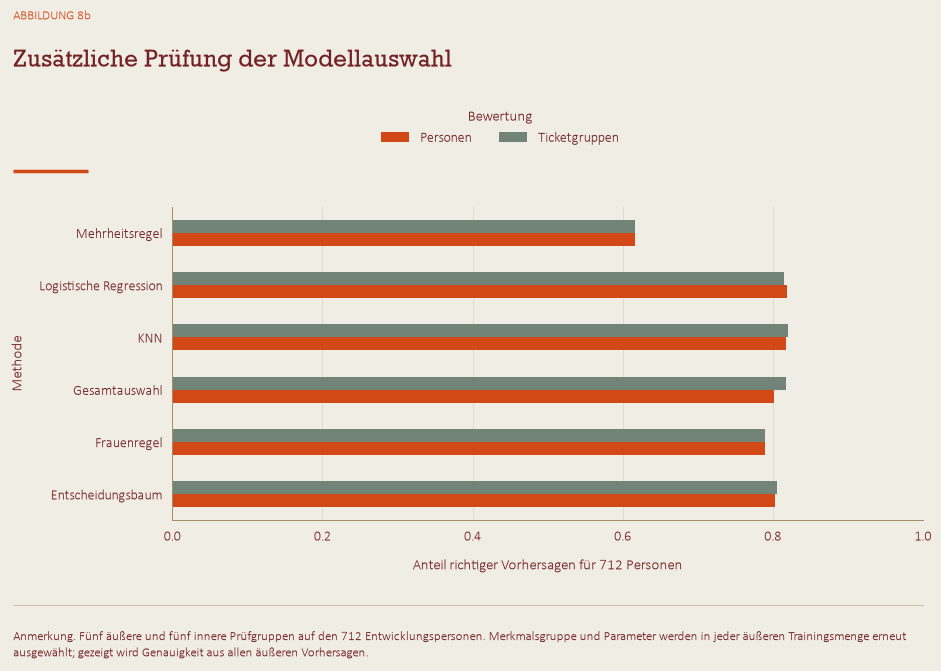

In [9]:
plot = summen.pivot(index='Methode', columns='Bewertung', values='Accuracy').rename(index=BEZEICHNUNGEN)
fig, ax = plt.subplots(figsize=(10, 7))
plot.plot.barh(ax=ax, color=[COLORS['accent1'], COLORS['accent3']])
ax.set(xlabel='Anteil richtiger Vorhersagen für 712 Personen', xlim=(0, 1), title='Zusätzliche Prüfung der Modellauswahl')
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
fig.legend(handles, labels, title='Bewertung', ncol=2)
ax.set_title('')
save_leaf_figure(fig, '8b', 'Zusätzliche Prüfung der Modellauswahl', 'Fünf äußere und fünf innere Folds auf den 712 Entwicklungspersonen. Featuregruppe und Parameter werden in jeder äußeren Trainingsmenge erneut ausgewählt; gezeigt wird Accuracy aus allen äußeren Vorhersagen.', ABBILDUNGEN / '08_nested_alle_modelle')



## Auswahl für Notebook 4 festhalten

Wir speichern die ausgewählten Merkmale und Einstellungen. Notebook 4 baut daraus die drei Modelle auf und erklärt ihre Vorhersagen. Eine neue Auswahl erfolgt dort nicht.


In [10]:
saved = []
for _, row in top3.iterrows():
    record = row.to_dict()
    record['Parameter'] = json.loads(record['Parameter'])
    saved.append(record)
best_types = {}
for model_type in MODEL_TYPES:
    record = selected_row(suchverlauf, model_type=model_type).to_dict()
    record['Parameter'] = json.loads(record['Parameter'])
    best_types[model_type] = record
selection = {'Top3': saved, 'Beste_Modelltypen': best_types, 'Auswahlregel': 'Höchster mittlerer Anteil richtiger Vorhersagen je Ansatz; bei Gleichstand geringere Streuung, danach Kandidatenreihenfolge', 'Featuregruppen': len(gruppen), 'Modelle_in_Suche': len(MODEL_TYPES), 'Konfigurationen_pro_Suche': len(suchverlauf), 'Modell': saved[0]['Modell'], 'Merkmalsgruppe': saved[0]['Merkmalsgruppe'], 'Parameter': saved[0]['Parameter'], 'Auswahl_CV_Accuracy': saved[0]['CV-Accuracy']}
(ERGEBNISSE / 'modell_auswahl.json').write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print(deutsch('Die Auswahl ist gespeichert. Weiter mit 04_Gewinner_Modell.ipynb.'))



Die Auswahl ist gespeichert. Weiter mit 04_Gewinner_Modell.ipynb.


## Quellen

Daten: `train.csv` und `test.csv`. Aufgabenstellung: `Task_description.pdf`. Fachliche Grundlage: Lisa Grobelscheg, *Skriptum LV DSM, ITW 26/27* (`Skriptum.pdf`).

KI-Unterstützung wurde für Code, Abbildungen und Erklärungen verwendet.
